# Scratch100k taxv2: loss weight 0.5 and KL + partial CE

Follow-up to `Scratch100k_TaxV2_Results.ipynb`. Same recipe and the same fixed concept table (703 channels, pinned CSV
sha1 `d46f6fe…`): 75k updates at constant LR then a 25k cooldown, 256 px, dedup CoralNet splits, data seed 4. New runs:
- **distance / KL / partial CE at w=0.5** (`sbatch slurm/scratch100k_train.sbatch <LOSS> 0.5 tag=taxv2`),
- **KL w=0.5 + partial CE w=0.1** in one run (`sbatch slurm/scratch100k_train.sbatch klpartial 0.5 0.1 tag=taxv2`).

They are compared with base and the w=0.1 runs from the earlier notebook. All runs here are on the same tree, so every
metric compares directly. Colours: hue = loss; w=0.1 lighter and dashed, w=0.5 full colour and solid; KL + partial CE in
purple. One seed per configuration, so differences of 1–2 pp are within the step-to-step noise seen before.

Figures for the same data: `eval_out/scratch100k_hier/plots_taxv2_weights/`
(`scripts/plot_hierarchical_evals.py --runs '.*_taxv2' --out-dir ...`).

In [1]:
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

REPO = Path("..").resolve() if Path("../eval_out").exists() else Path(".").resolve()
ROOT = REPO / "eval_out/scratch100k_hier"
CKPTS = REPO / "nbs/model_checkpoints"
PREFIX = "cbm_scratch100k_"
TAG = "taxv2"
RES = 256
RANKS = ["kingdom", "phylum", "class", "order", "family", "genus"]
PAIRS = [f"{c}->{f}" for c, f in zip(RANKS, RANKS[1:])]
EVALS = {"coralnet": "CoralNet val (dedup)", "pacific": "Pacific val"}
COOLDOWN = (75000, 100000)  # linear LR cooldown to 0
REF = f"base_{TAG}"

# Hue = loss, as in scripts/plot_hierarchical_evals.py. w=0.1: lighter + dashed; w=0.5 (and the combined run): full
# colour + solid, so weight is never colour-only.
LOSSES = {
    "base": ("base", "#2a78d6", "o"),
    "distance": ("distance", "#eb6834", "s"),
    "kl": ("KL", "#1baf7a", "^"),
    "partial": ("partial CE", "#eda100", "D"),
    "klpartial": ("KL + partial CE", "#8a4fd0", "P"),
}
INK, MUTED, GRID, BAND, SURFACE = "#1c1c1a", "#6b6a64", "#e4e3df", "#ebeae6", "#fcfcfb"


def shade(color, mix):
    rgb = [int(color[i:i + 2], 16) for i in (1, 3, 5)]
    target = 255 if mix > 0 else 0
    return "#" + "".join(f"{round(c + (target - c) * abs(mix)):02x}" for c in rgb)


def parse(run):
    """'kl_w0.5_taxv2' -> ('kl', '0.5'); 'klpartial_w0.5_0.1_taxv2' -> ('klpartial', '0.5_0.1')."""
    loss, _, weight = run.removesuffix("_" + TAG).partition("_w")
    return loss, weight


def style(run):
    """(label, colour, marker, linestyle) of a short run name."""
    loss, weight = parse(run)
    name, color, marker = LOSSES[loss]
    if not weight:
        return name, color, marker, "-"
    label = f"{name} w={weight.replace('_', '/')}"
    if weight == "0.1":
        return label, shade(color, 0.35), marker, "--"
    return label, color, marker, "-"


def order(run):
    loss, weight = parse(run)
    return list(LOSSES).index(loss), float(weight.split("_")[0] or 0)


plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlecolor": INK, "axes.titlesize": 10, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.frameon": False, "figure.dpi": 100,
})
pd.set_option("display.width", 200)

df = pd.read_csv(ROOT / "compiled.csv")
df = df[df.resolution == RES].copy()
df["run"] = df.run.str.removeprefix(PREFIX)
RUNS = sorted((r for r in df.run.unique() if r.endswith("_" + TAG)), key=order)
df = df[df.run.isin(RUNS)].sort_values(["run", "step"]).set_index(["run", "step"])
EVALUATED = {r: sorted(df.loc[r].index) for r in RUNS}
STEPS = sorted({s for r in RUNS for s in EVALUATED[r]})
COMPARE = [r for r in RUNS if r != REF]
W01 = [r for r in COMPARE if parse(r)[1] == "0.1"]
W05 = [r for r in COMPARE if parse(r)[1] != "0.1"]  # w=0.5 runs and the combined run


def plot_run(ax, run, x, y, **kw):
    label, color, marker, ls = style(run)
    ax.plot(x, y, color=color, marker=marker, ls=ls, lw=2, ms=6, mec="white", mew=0.8, label=label, **kw)


def step_axis(ax, steps):
    ax.set_xticks(steps)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{int(v / 1000)}k"))
    if steps[-1] > COOLDOWN[0]:
        ax.axvspan(*COOLDOWN, color=BAND, lw=0, zorder=0)


def run_legend(fig, runs, y=1.0, ncol=None):
    handles = [Line2D([], [], color=style(r)[1], marker=style(r)[2], ls=style(r)[3], lw=2, label=style(r)[0]) for r in runs]
    fig.legend(handles=handles, loc="upper right", ncol=ncol or len(handles), bbox_to_anchor=(1, y), fontsize=9)


def delta(run, col, ref=REF):
    """run − ref at the steps both have (raw units), as a Series indexed by step."""
    a, b = df.loc[run, col], df.loc[ref, col]
    common = [s for s in a.index if s in b.index]
    return a.loc[common] - b.loc[common]


print("runs:", RUNS)
print("steps evaluated:", STEPS)

runs: ['base_taxv2', 'distance_w0.1_taxv2', 'distance_w0.5_taxv2', 'kl_w0.1_taxv2', 'kl_w0.5_taxv2', 'partial_w0.1_taxv2', 'partial_w0.5_taxv2', 'klpartial_w0.5_0.1_taxv2']
steps evaluated: [25000, 50000, 75000, 100000]


## 0. What has been evaluated
Checkpoints on disk and finished evals (rows of `compiled.csv`), and the checksum of each run's pinned concept CSV: all
should match.

In [2]:
on_disk = {}
for d in sorted(CKPTS.glob(PREFIX + "*")):
    name = d.name.removeprefix(PREFIX)
    run = name.removesuffix("_cd")
    if run not in RUNS:
        continue
    for ck in d.glob("model_epoch*"):
        epoch = int(ck.name.removeprefix("model_epoch"))
        step = 100000 + 25000 * epoch if name.endswith("_cd") else 25000 * (epoch + 1)
        on_disk.setdefault(run, set()).add(step)


def csv_sha(run):
    p = CKPTS / f"{PREFIX}{run}/class_to_concepts.csv"
    return hashlib.sha1(p.read_bytes()).hexdigest()[:12] if p.exists() else "—"


status = pd.DataFrame(
    [[("evaluated" if s in EVALUATED.get(r, []) else "ckpt, not evaluated" if s in on_disk.get(r, set()) else "—")
      for s in (25000, 50000, 75000, 100000)] + [csv_sha(r)] for r in RUNS],
    index=[style(r)[0] for r in RUNS], columns=["25k", "50k", "75k", "100k (cooldown)", "pinned CSV sha1"])
status

,25k,50k,75k,100k (cooldown),pinned CSV sha1
base,evaluated,evaluated,evaluated,evaluated,d46f6fe76c31
distance w=0.1,evaluated,evaluated,evaluated,evaluated,d46f6fe76c31
distance w=0.5,evaluated,evaluated,evaluated,evaluated,d46f6fe76c31
KL w=0.1,evaluated,evaluated,evaluated,evaluated,d46f6fe76c31
KL w=0.5,evaluated,evaluated,evaluated,evaluated,d46f6fe76c31
partial CE w=0.1,evaluated,evaluated,evaluated,evaluated,d46f6fe76c31
partial CE w=0.5,evaluated,evaluated,evaluated,evaluated,d46f6fe76c31
KL + partial CE w=0.5/0.1,evaluated,evaluated,evaluated,evaluated,d46f6fe76c31


## 1. Headline metrics, one row per loss
Each row: base, the loss at w=0.1 (dashed) and at w=0.5 (solid). The last row puts the combined run next to its two
ingredients, KL w=0.5 and partial CE w=0.1. Grey = LR cooldown.

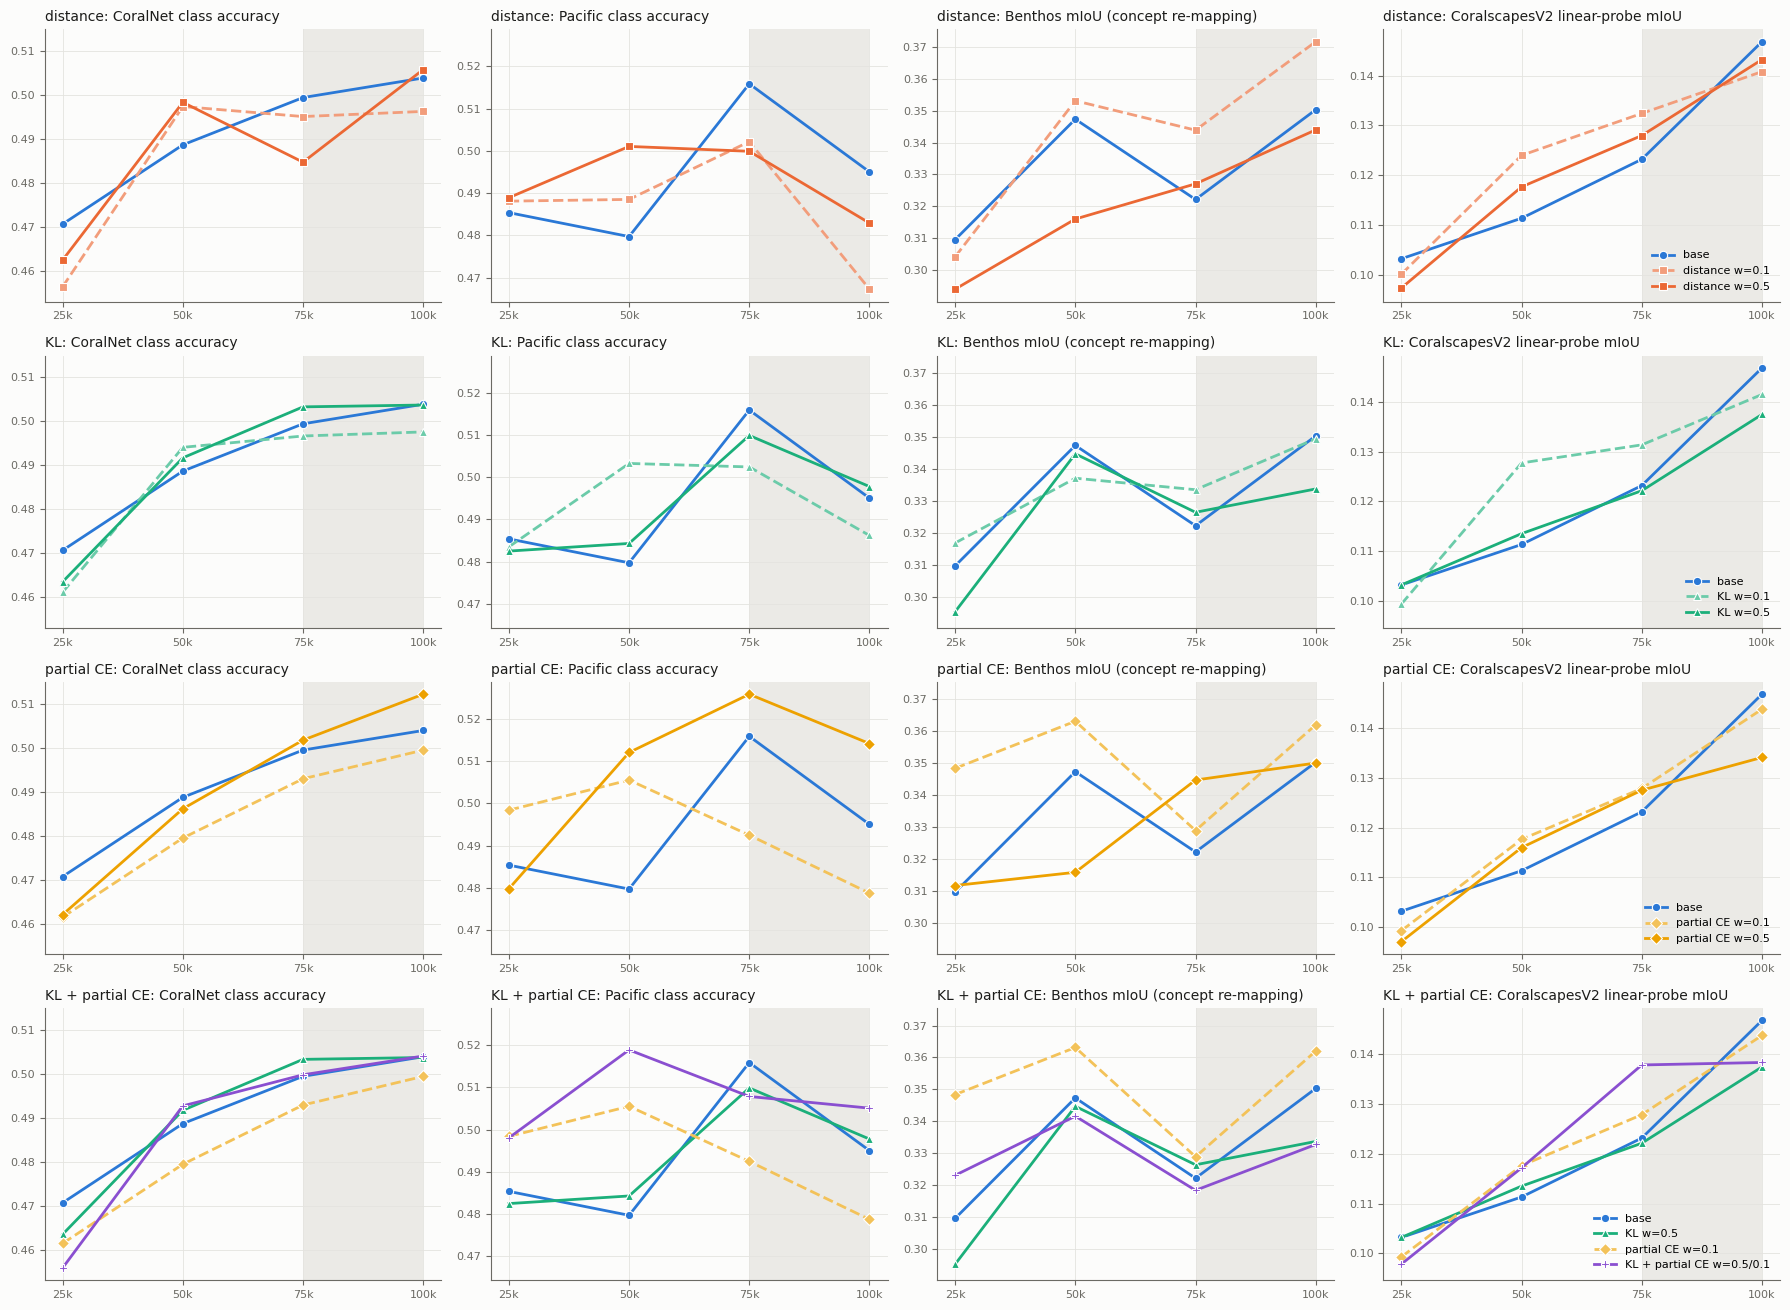

In [3]:
HEADLINE = [
    ("coralnet/class_accuracy", "CoralNet class accuracy"),
    ("pacific/class_accuracy", "Pacific class accuracy"),
    ("benthos/miou", "Benthos mIoU (concept re-mapping)"),
    ("coralscapes/miou", "CoralscapesV2 linear-probe mIoU"),
]
FAMILIES = {
    "distance": [REF] + [r for r in COMPARE if parse(r)[0] == "distance"],
    "KL": [REF] + [r for r in COMPARE if parse(r)[0] == "kl"],
    "partial CE": [REF] + [r for r in COMPARE if parse(r)[0] == "partial"],
    "KL + partial CE": [REF, "kl_w0.5_taxv2", "partial_w0.1_taxv2", "klpartial_w0.5_0.1_taxv2"],
}
fig, axes = plt.subplots(len(FAMILIES), len(HEADLINE), figsize=(18, 3.3 * len(FAMILIES)), sharey="col")
for row, (fam, runs) in zip(axes, FAMILIES.items()):
    runs = [r for r in runs if r in RUNS]
    for ax, (col, name) in zip(row, HEADLINE):
        for run in runs:
            d = df.loc[run, col]
            plot_run(ax, run, d.index, d.values)
        ax.set_title(f"{fam}: {name}")
        step_axis(ax, STEPS)
    row[-1].legend(fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()

**Reading** (all four checkpoints; 75k → 100k is the LR cooldown).
- **CoralNet class accuracy at 100k**: partial CE w=0.5 0.512, distance w=0.5 0.506, KL w=0.5 0.504, KL + partial CE 0.504,
  base 0.504. At w=0.1 all three losses ended below base (0.496–0.499). At w=0.5 they all end level with it or ahead, and
  each w=0.5 run beats its w=0.1 run at 100k (+0.6 to +1.3 pp). Partial CE w=0.5 is the only run clearly above base, and
  only at 75k and 100k.
- **Pacific class accuracy at 100k**: partial CE w=0.5 0.514, KL + partial CE 0.505, KL w=0.5 0.498, base 0.495, distance
  w=0.5 0.483. Partial CE w=0.5 is ahead of base at 50k, 75k and 100k (+1.0 to +3.2 pp). As before, Pacific moves by 2–4 pp
  between checkpoints, so its order is not reliable from one seed.
- **Benthos is lower with the higher weight.** At 100k the w=0.5 runs and the combined run score 0.333–0.350 against base
  0.350, while distance and partial CE at w=0.1 were above base (0.372 / 0.362).
- **CoralscapesV2**: base stays highest at 100k (0.147); every loss run ends at 0.134–0.144.

## 2. Scorecard: each run vs base
`run − base [taxv2]` in percentage points, averaged over the steps both have; whiskers are the min / max over steps (a
whisker crossing 0 means the sign is not stable). Rows are oriented so **right = better**.

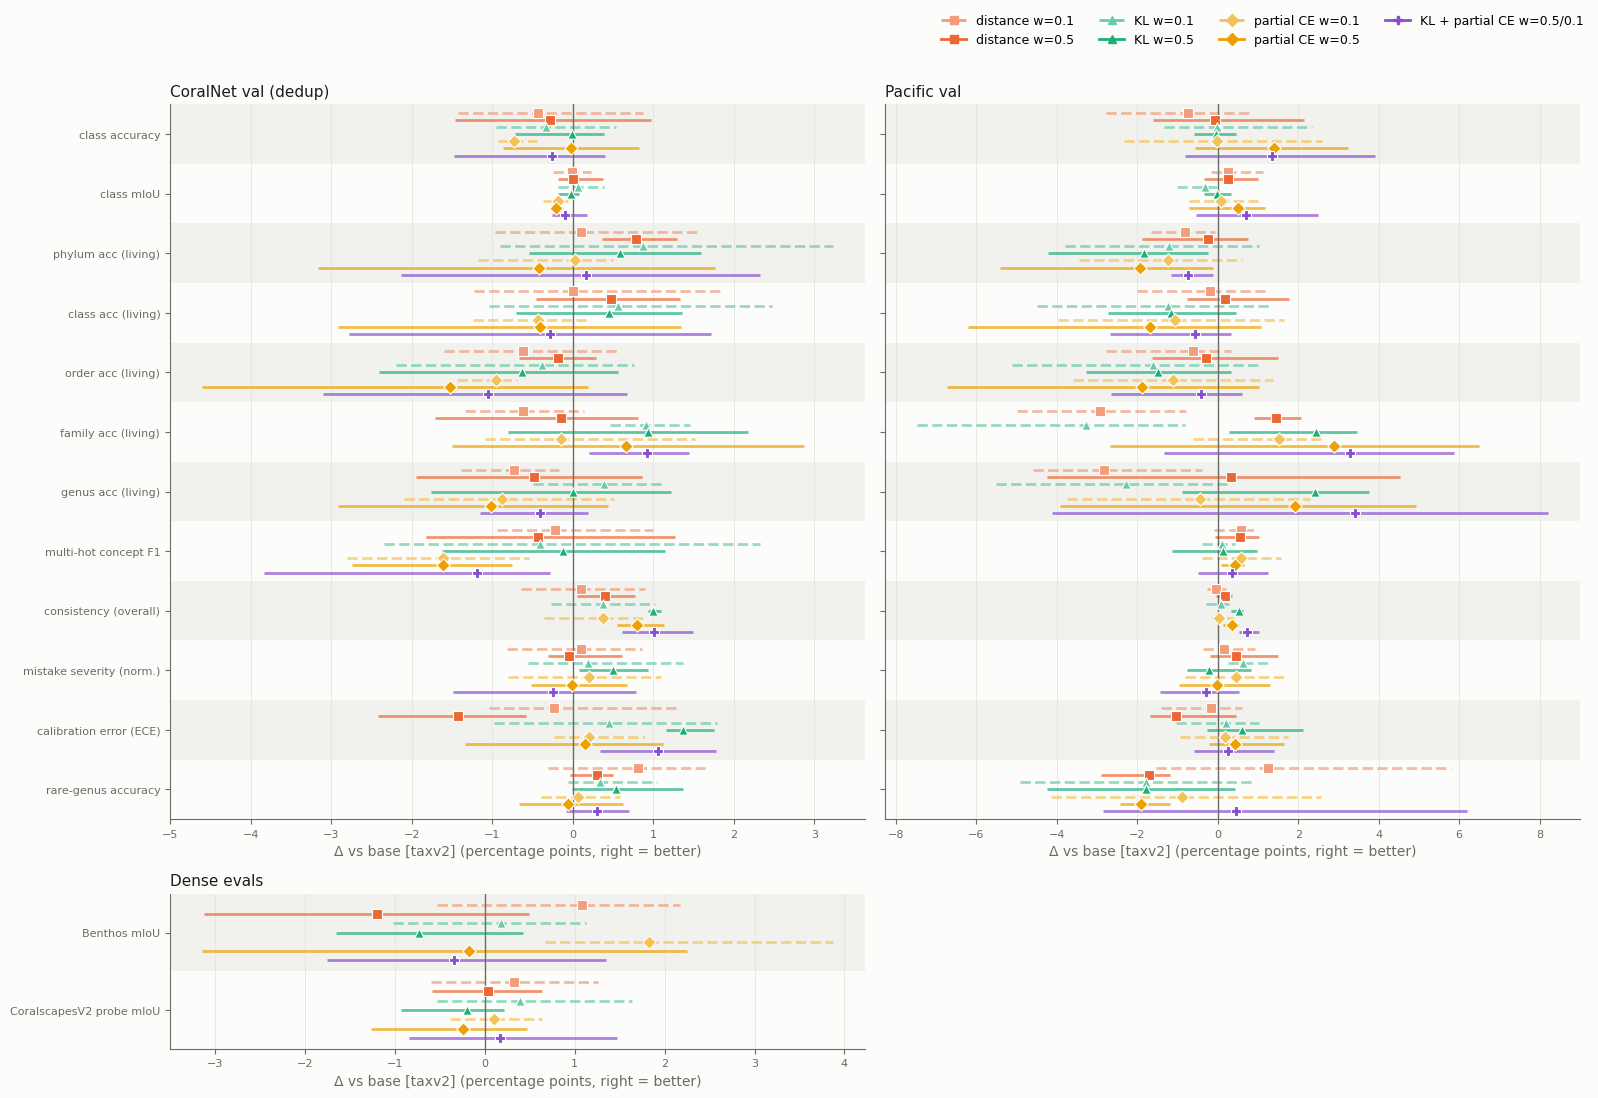

run,distance w=0.1,distance w=0.5,KL w=0.1,KL w=0.5,partial CE w=0.1,partial CE w=0.5,KL + partial CE w=0.5/0.1
metric,,,,,,,
CoralNet class accuracy,-0.4,-0.3,-0.3,-0.0,-0.7,-0.0,-0.3
CoralNet class mIoU,-0.0,-0.0,+0.1,-0.0,-0.2,-0.2,-0.1
CoralNet phylum acc (living),+0.1,+0.8,+0.9,+0.6,+0.0,-0.4,+0.2
CoralNet class acc (living),+0.0,+0.5,+0.6,+0.5,-0.4,-0.4,-0.3
CoralNet order acc (living),-0.6,-0.2,-0.4,-0.6,-1.0,-1.5,-1.1
CoralNet family acc (living),-0.6,-0.1,+0.9,+0.9,-0.1,+0.7,+0.9
CoralNet genus acc (living),-0.7,-0.5,+0.4,+0.0,-0.9,-1.0,-0.4
CoralNet multi-hot concept F1,-0.2,-0.4,-0.4,-0.1,-1.6,-1.6,-1.2
CoralNet consistency (overall),+0.1,+0.4,+0.4,+1.0,+0.4,+0.8,+1.0


In [4]:
SCORECARD = [  # (column suffix, label, higher_is_better)
    ("class_accuracy", "class accuracy", True),
    ("class_miou", "class mIoU", True),
    *[(f"tax_{r}_acc_living", f"{r} acc (living)", True) for r in RANKS[1:]],
    ("binary_macro_f1", "multi-hot concept F1", True),
    ("consistency/overall", "consistency (overall)", True),
    ("severity/mean_normalized", "mistake severity (norm.)", False),
    ("ece/mean", "calibration error (ECE)", False),
    ("rare/genus/tail_macro_acc", "rare-genus accuracy", True),
]
OFFSETS = dict(zip(COMPARE, np.linspace(-0.36, 0.36, len(COMPARE))))


def scorecard(cols, runs=COMPARE):
    rows = []
    for col, label, hib in cols:
        for run in runs:
            d = (1 if hib else -1) * delta(run, col) * 100
            rows.append(dict(metric=label, run=run, mean=d.mean(), lo=d.min(), hi=d.max(), n=len(d)))
    return pd.DataFrame(rows)


def draw_scorecard(ax, sc, labels, title):
    y = {lab: i for i, lab in enumerate(labels)}
    for i in range(0, len(labels), 2):
        ax.axhspan(i - 0.5, i + 0.5, color=BAND, lw=0, zorder=0, alpha=0.6)
    for run, off in OFFSETS.items():
        _, color, marker, ls = style(run)
        s = sc[sc.run == run]
        yy = np.array([y[m] for m in s.metric]) + off
        ax.hlines(yy, s.lo, s.hi, color=color, lw=2, alpha=0.7, linestyles="--" if ls == "--" else "-")
        ax.scatter(s["mean"], yy, color=color, marker=marker, s=46, edgecolor="white", linewidth=0.8, zorder=3)
    ax.axvline(0, color=MUTED, lw=1)
    ax.set_yticks(range(len(labels)), labels)
    ax.set_ylim(len(labels) - 0.5, -0.5)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Δ vs base [taxv2] (percentage points, right = better)")
    ax.set_title(title, fontsize=11)


fig = plt.figure(figsize=(16, 11))
gs = fig.add_gridspec(2, 2, height_ratios=[len(SCORECARD), 2.6])
labels = [lab for _, lab, _ in SCORECARD]
for i, ev in enumerate(EVALS):
    ax = fig.add_subplot(gs[0, i])
    draw_scorecard(ax, scorecard([(f"{ev}/{c}", l, h) for c, l, h in SCORECARD]), labels, EVALS[ev])
    if i:
        ax.set_yticklabels([])
DENSE = [("benthos/miou", "Benthos mIoU", True), ("coralscapes/miou", "CoralscapesV2 probe mIoU", True)]
draw_scorecard(fig.add_subplot(gs[1, 0]), scorecard(DENSE), [l for _, l, _ in DENSE], "Dense evals")
run_legend(fig, COMPARE, ncol=4)
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

sc = scorecard([(f"{ev}/{c}", f"{EVALS[ev].split(' ')[0]} {l}", h) for ev in EVALS for c, l, h in SCORECARD] + DENSE)
sc["run"] = sc.run.map(lambda r: style(r)[0])
(sc.pivot(index="metric", columns="run", values="mean").loc[sc.metric.unique(), [style(r)[0] for r in COMPARE]]
 .style.format("{:+.1f}").background_gradient(cmap="RdBu", vmin=-4, vmax=4, axis=None)
 .set_caption("mean Δ vs base [taxv2] over 25k–100k, pp, right = better (sign-flipped for ECE / severity)"))

**Reading** (averages over 25k–100k; a row counts as stable only if all four checkpoints are on the same side of 0).
- **KL w=0.5 has the most stable gains**: CoralNet consistency +1.0 pp (+0.9 to +1.1 at every step), Pacific consistency
  +0.5 pp, CoralNet calibration error 1.4 pp lower (better at every step), and CoralNet mistake severity slightly better
  (+0.5 pp). Its class accuracy averages level with base on both datasets.
- **The higher weight reverses the Pacific family deficit.** At w=0.1, KL and distance were below base on Pacific family
  accuracy at every step (−3.3 / −2.9 pp). At w=0.5 both are above it at every step (KL +2.4, distance +1.4). Partial CE
  w=0.5 (+2.9) and the combined run (+3.3) average higher still, but their sign is not stable across steps.
- **Costs that hold at every step**:
  - Pacific phylum accuracy is lower for KL w=0.5 (−1.8 pp), partial CE w=0.5 (−1.9) and the combined run (−0.7). Most
    of this comes from 25k–50k (up to −5.4 pp); at 100k all three are within 0.2 pp of base.
  - CoralNet multi-hot concept F1 is lower for every run with a partial CE term (−1.2 to −1.6 pp).
  - Pacific rare-genus accuracy is lower for distance w=0.5 (−1.7) and partial CE w=0.5 (−1.9).
  - Distance w=0.5 has 1.4 pp worse CoralNet calibration error.
- **The combined run** matches KL w=0.5's stable gains (CoralNet family accuracy +0.9 pp, consistency +1.0 / +0.7, CoralNet
  ECE 1.1 pp better). It adds Pacific class accuracy (+1.3 pp on average), but that gain is not stable across steps.

## 3. What the higher weight changes, and what combining adds
`w=0.5 − w=0.1` for each loss, and the combined run minus each of its ingredients, in percentage points at each
step. Rows marked ↓: negative is better.

In [5]:
PAIRS_CMP = [  # (run, against, label)
    ("distance_w0.5_taxv2", "distance_w0.1_taxv2", "distance 0.5 − 0.1"),
    ("kl_w0.5_taxv2", "kl_w0.1_taxv2", "KL 0.5 − 0.1"),
    ("partial_w0.5_taxv2", "partial_w0.1_taxv2", "partial CE 0.5 − 0.1"),
    ("klpartial_w0.5_0.1_taxv2", "kl_w0.5_taxv2", "KL+pCE − KL 0.5"),
    ("klpartial_w0.5_0.1_taxv2", "partial_w0.1_taxv2", "KL+pCE − pCE 0.1"),
]
CMP_ROWS = [  # (column suffix, label)
    ("class_accuracy", "class acc"),
    *[(f"tax_{r}_acc_living", f"{r} acc (living)") for r in ("phylum", "family", "genus")],
    ("consistency/overall", "consistency (overall)"),
    ("severity/mean_normalized", "mistake severity ↓"),
    ("ece/mean", "ECE ↓"),
]
rows = []
for run, against, label in PAIRS_CMP:
    if run not in RUNS or against not in RUNS:
        continue
    for step in sorted(set(EVALUATED[run]) & set(EVALUATED[against])):
        r = {"comparison": label, "step": f"{step // 1000}k"}
        for ev in EVALS:
            for suffix, name in CMP_ROWS:
                col = f"{ev}/{suffix}"
                r[(EVALS[ev].split(" ")[0], name)] = 100 * (df.loc[(run, step), col] - df.loc[(against, step), col])
        for col, name in (("benthos/miou", "Benthos mIoU"), ("coralscapes/miou", "CoralscapesV2 mIoU")):
            r[("dense", name)] = 100 * (df.loc[(run, step), col] - df.loc[(against, step), col])
        rows.append(r)
cmp = pd.DataFrame(rows).set_index(["comparison", "step"])
cmp.columns = pd.MultiIndex.from_tuples(cmp.columns)
(cmp.T.style.format("{:+.1f}").background_gradient(cmap="RdBu", vmin=-4, vmax=4, axis=None)
 .set_caption("pp; ↓ rows: negative is better"))

**Reading.**
- **Going from 0.1 to 0.5 mainly helps Pacific family and genus.** KL improves at every step: family +3.8 to +10.5 pp, genus
  +3.1 to +5.8 pp. Distance improves family at every step (+2.4 to +6.8 pp). Partial CE is worse at 25k (−4.5 / −3.7) and
  better afterwards, by up to +8.7 pp on genus at 100k.
- **CoralNet class accuracy is higher at w=0.5 at 100k** for all three losses (+0.6 to +1.3 pp), and every 25k–75k
  difference is within ±1 pp.
- **Benthos is lower at w=0.5 at 10 of 12 checkpoints** (all four for distance, three each for KL and partial CE), by up
  to 4.7 pp.
- **Calibration depends on the loss.** A higher KL weight lowers CoralNet ECE at three of four steps (by up to 2.2 pp). A
  higher distance weight raises it at three of four (+1.2 to +2.2 pp).
- **KL + partial CE vs KL w=0.5 alone**: CoralNet differences are within ±1 pp with mixed signs. Pacific class accuracy is
  higher at three of four steps (+0.7 to +3.5 pp), but Pacific family and genus swing from −7.6 to +5.6 pp. Adding partial
  CE w=0.1 to KL does not give a consistent improvement.
- **KL + partial CE vs partial CE w=0.1 alone**: adding KL lowers ECE at every CoralNet step (−0.6 to −1.1 pp) and raises
  CoralNet family and genus accuracy at three of four steps. It costs Benthos mIoU at every step (−1.1 to −2.9 pp).

## 4. Each loss's own objective
Absolute values on CoralNet, averaged over ranks / rank pairs. Each loss should move its own row.

In [6]:
OBJ = {
    "expected tree distance ↓ (mean over ranks)": [f"coralnet/expected_distance/{r}" for r in RANKS],
    "inter-head KL ↓ (mean over pairs)": [f"coralnet/kl/{p}" for p in PAIRS],
    "partial-label subtree mass ↑ (mean over pairs)": [f"coralnet/partial/{p}/subtree_mass" for p in PAIRS],
}
obj = pd.DataFrame({
    (name, f"{s // 1000}k"): df[cols].mean(axis=1).xs(s, level="step")
    for name, cols in OBJ.items() for s in STEPS
}).reindex(RUNS)
obj.index = [style(r)[0] for r in obj.index]
obj.style.format("{:.3f}", na_rep="—").set_caption("CoralNet val")

**Reading** (CoralNet; Pacific shows the same pattern).
- **KL w=0.5 holds the inter-head KL at 0.015 nats at every step.** That is less than half of w=0.1 (0.035 at 100k) and a
  fifth of base (0.083); on Pacific it is 0.011 vs 0.031 and 0.107. The combined run is the same (0.014). Partial CE w=0.5
  does not lower KL beyond w=0.1 (0.043 vs 0.042 at 100k).
- **KL w=0.5 also raises partial-label subtree mass more than partial CE w=0.5 does** (0.293 vs 0.280 at 100k; base 0.226),
  even though subtree mass is partial CE's own objective. The combined run is barely higher than KL alone (0.299). So in the
  combined run the KL term does nearly all the work, and partial CE at w=0.1 adds little to either objective.
- **Distance w=0.5 now lowers its own objective.** Expected tree distance is below base from 50k on (0.223 vs 0.234 at
  100k); at w=0.1 it never moved. KL and the combined run have the highest expected tree distance (0.240 / 0.241).

## 5. Per-rank differences vs base
`run − base [taxv2]` at each checkpoint, in raw units. Rows: per-rank accuracy on living points, lineage consistency per
rank pair, normalised mistake severity, and the three loss objectives.

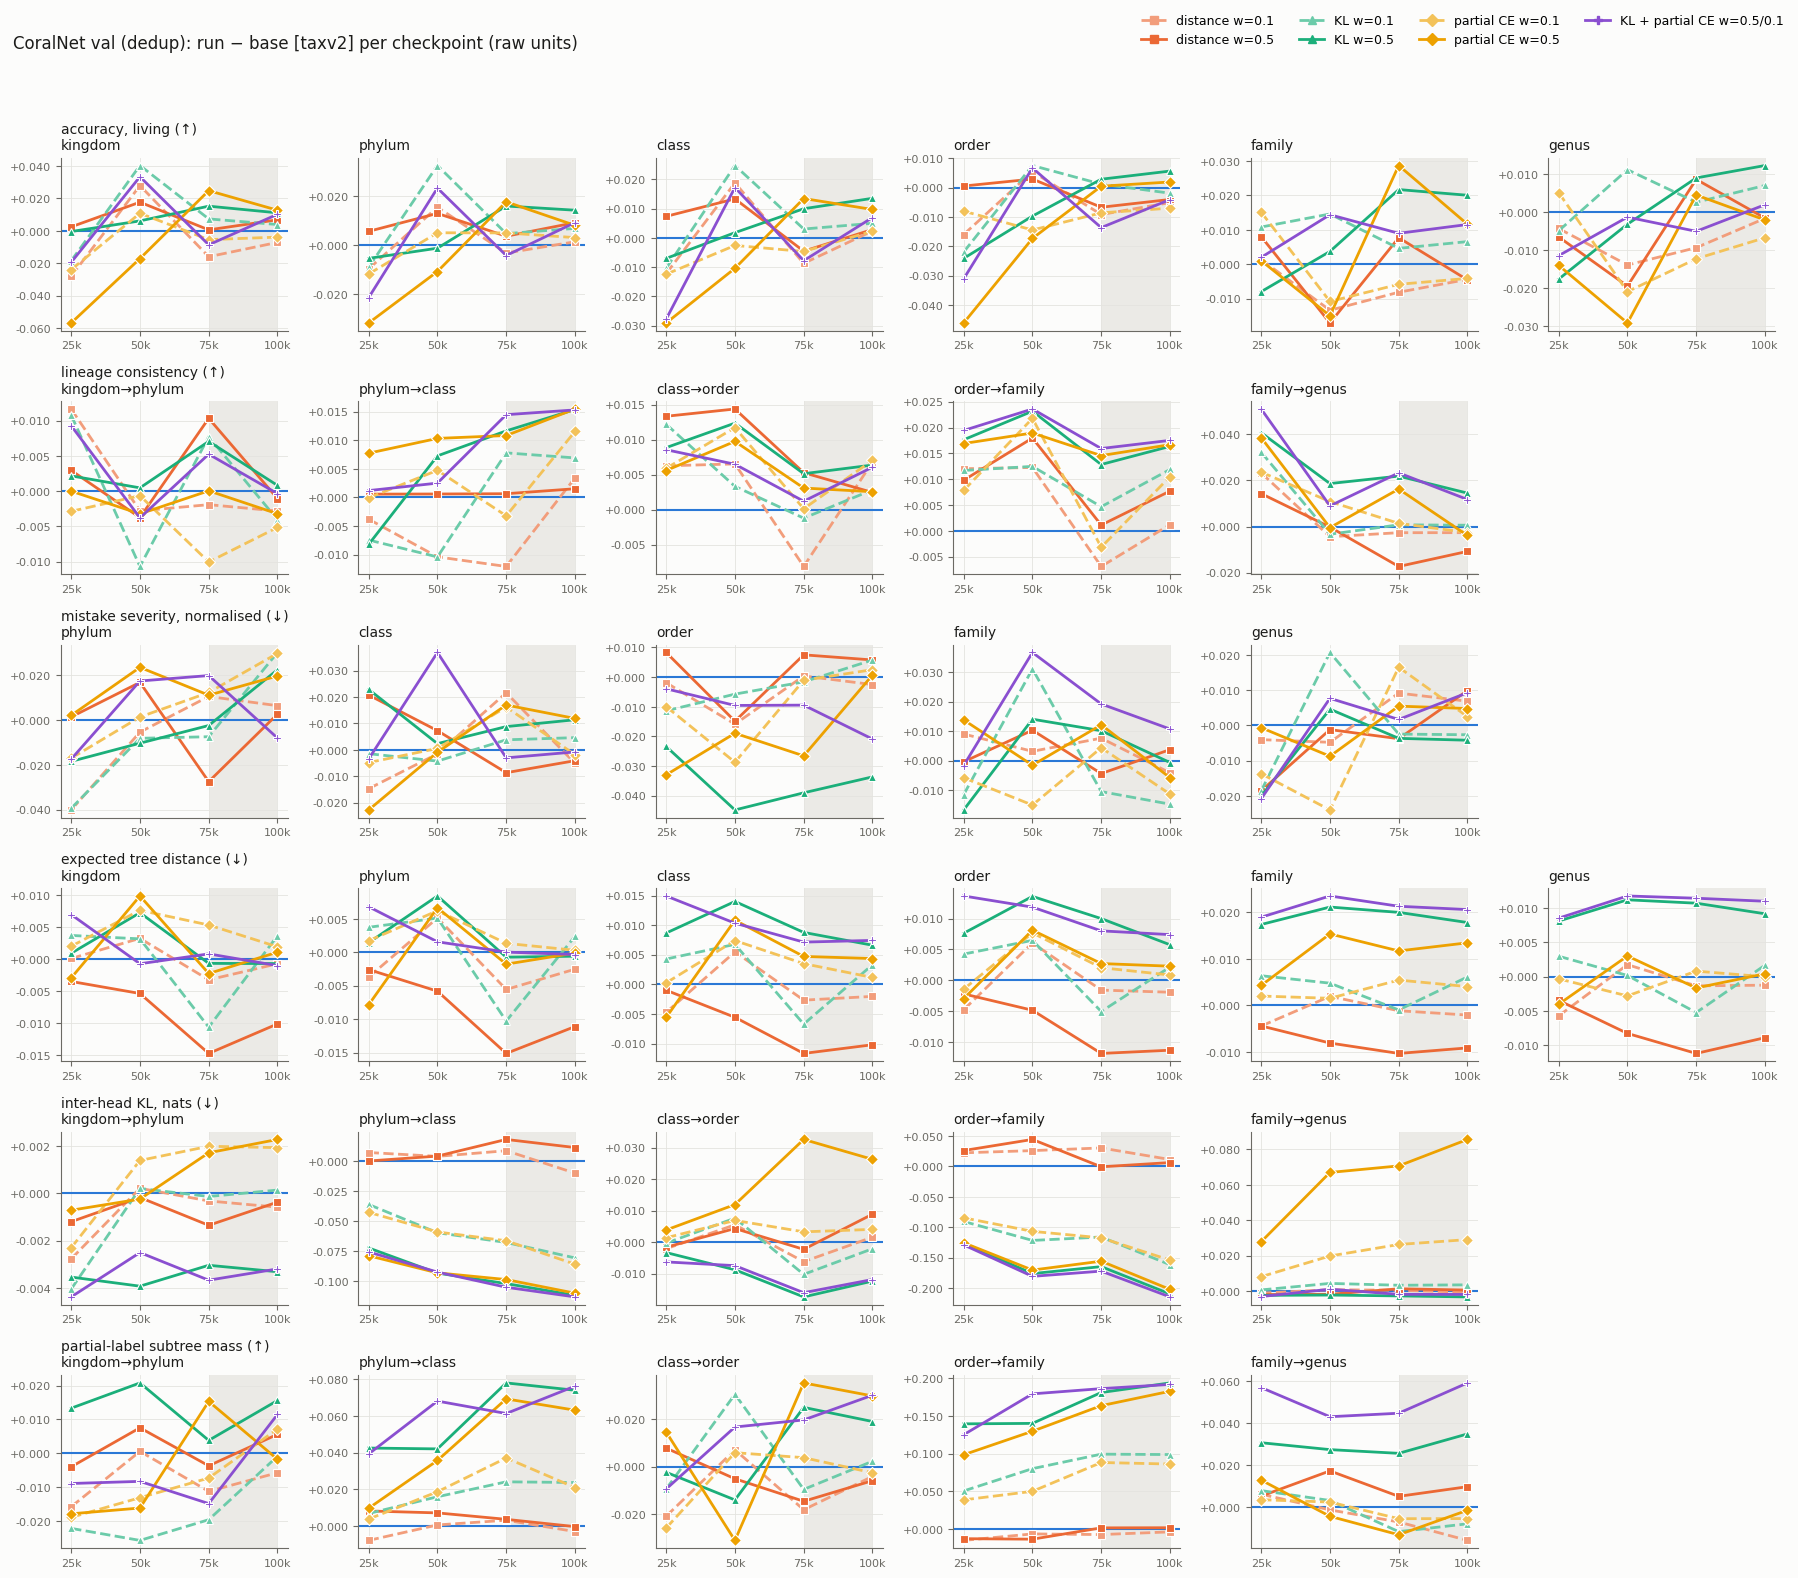

In [7]:
DELTA_ROWS = [  # (title, [(suffix, panel label)])
    ("accuracy, living (↑)", [(f"tax_{r}_acc_living", r) for r in RANKS]),
    ("lineage consistency (↑)", [(f"consistency/{p}", p.replace("->", "→")) for p in PAIRS]),
    ("mistake severity, normalised (↓)", [(f"severity/{r}/normalized", r) for r in RANKS[1:]]),
    ("expected tree distance (↓)", [(f"expected_distance/{r}", r) for r in RANKS]),
    ("inter-head KL, nats (↓)", [(f"kl/{p}", p.replace("->", "→")) for p in PAIRS]),
    ("partial-label subtree mass (↑)", [(f"partial/{p}/subtree_mass", p.replace("->", "→")) for p in PAIRS]),
]


def plot_deltas(ev):
    fig, axes = plt.subplots(len(DELTA_ROWS), 6, figsize=(18, 2.5 * len(DELTA_ROWS) + 0.8))
    for row_axes, (row_title, panels) in zip(axes, DELTA_ROWS):
        for i, ax in enumerate(row_axes):
            if i >= len(panels):
                ax.axis("off")
                continue
            suffix, label = panels[i]
            col = f"{ev}/{suffix}"
            ax.axhline(0, color=LOSSES["base"][1], lw=1.5)
            for run in COMPARE:
                d = delta(run, col)
                plot_run(ax, run, d.index, d.values)
            ax.set_title(label if i else f"{row_title}\n{label}")
            ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%+.3f"))
            step_axis(ax, STEPS)
    run_legend(fig, COMPARE, ncol=4)
    fig.suptitle(f"{EVALS[ev]}: run − base [taxv2] per checkpoint (raw units)", x=0.01, ha="left", fontsize=12, color=INK)
    fig.tight_layout(rect=(0, 0, 1, 0.955))
    plt.show()


plot_deltas("coralnet")

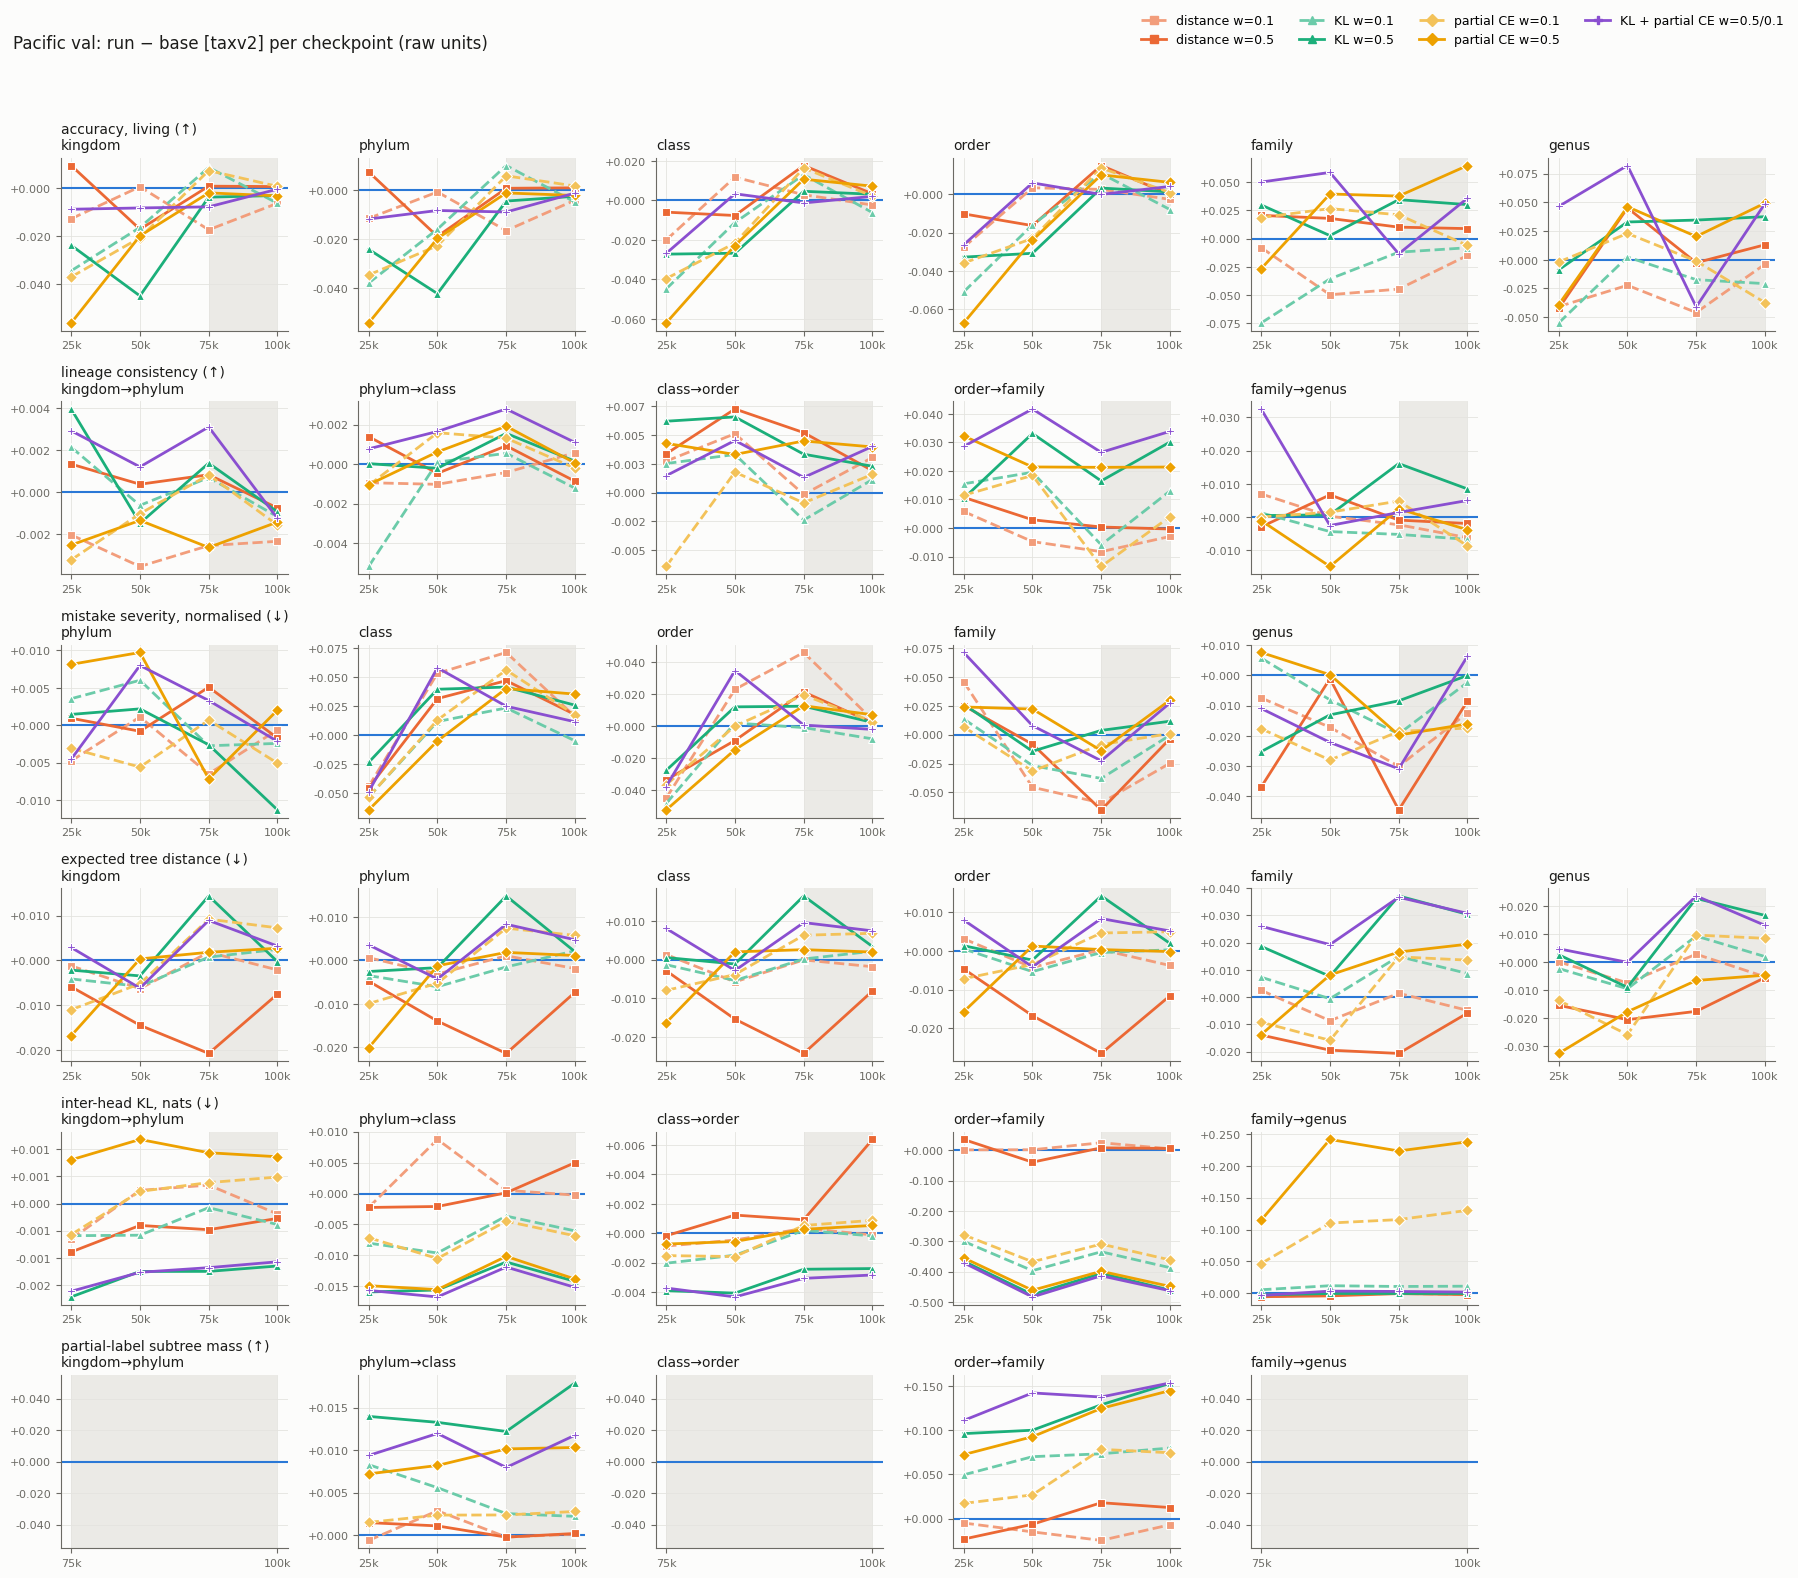

In [8]:
plot_deltas("pacific")

**Reading.**
- **Partial CE makes the family and genus heads disagree more.** Partial CE lowers the KL at the upper rank pairs, but at
  family→genus it raises it above base at every step: on CoralNet +0.029 nats at w=0.1 and +0.086 at w=0.5 (100k), on
  Pacific +0.13 and +0.24. This is why its mean KL in section 4 doesn't fall from w=0.1 to w=0.5. KL w=0.5 and the combined
  run stay at or below base at that pair, so in the combined run the KL term removes the problem.
- **Consistency**: KL w=0.5, partial CE w=0.5 and the combined run are above base at phylum→class, class→order and
  order→family at nearly every step. At family→genus only KL w=0.5 and the combined run stay above base at every step
  (+0.012 to +0.051 on CoralNet). Distance w=0.5 drops below base there from 75k (−0.011 to −0.017).
- **Pacific rank accuracy converges by the cooldown.** At 25k–50k the w=0.5 runs are 2–6 pp below base from kingdom to
  order. By 75k–100k they are within about 1 pp, while the family and genus gains of KL and partial CE w=0.5 remain.
- **Mistake severity**: KL w=0.5 makes less severe mistakes at order level on CoralNet at every step (−0.023 to −0.045).
  The other severity differences change sign between steps.
- **Expected tree distance**: distance w=0.5 is below base at every rank from 50k. KL w=0.5 and the combined run are above
  base from class to genus (+0.005 to +0.02).

## 6. Calibration and rare taxa
`run − base [taxv2]` for the mean ECE over ranks, and macro accuracy over head (common) and tail (rare) taxa at family and
genus.

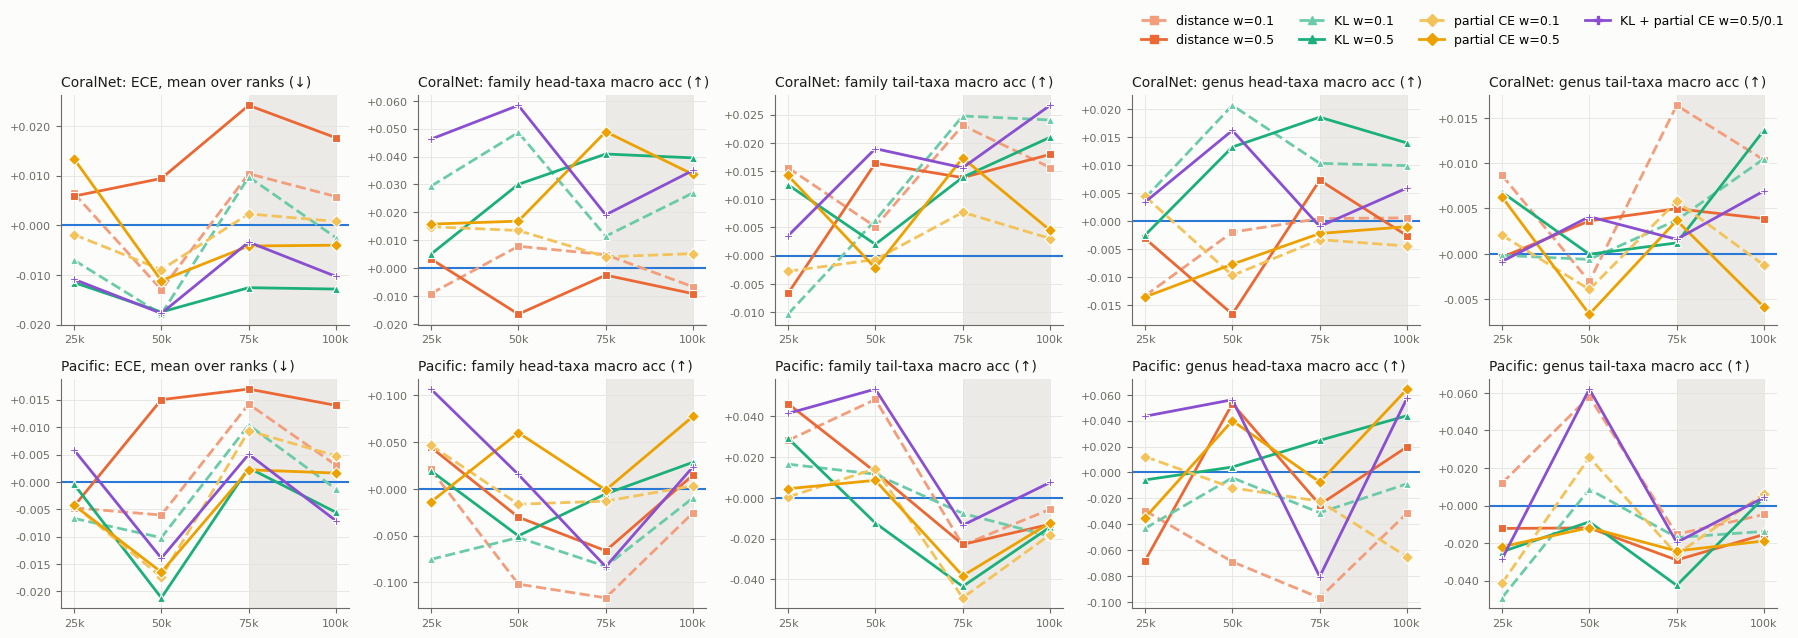

In [9]:
CALIB = [("ece/mean", "ECE, mean over ranks (↓)")] + [
    (f"rare/{r}/{s}_macro_acc", f"{r} {s}-taxa macro acc (↑)") for r in ("family", "genus") for s in ("head", "tail")]
fig, axes = plt.subplots(2, len(CALIB), figsize=(18, 6.4))
for row, ev in zip(axes, EVALS):
    for ax, (suffix, title) in zip(row, CALIB):
        ax.axhline(0, color=LOSSES["base"][1], lw=1.5)
        for run in COMPARE:
            d = delta(run, f"{ev}/{suffix}")
            plot_run(ax, run, d.index, d.values)
        ax.set_title(f"{EVALS[ev].split(' ')[0]}: {title}")
        ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%+.3f"))
        step_axis(ax, STEPS)
run_legend(fig, COMPARE, ncol=4)
fig.tight_layout(rect=(0, 0, 1, 0.91))
plt.show()

**Reading.**
- **ECE**: KL w=0.5 has the lowest CoralNet ECE at every step (0.043–0.053 vs base 0.055–0.067), and the combined run is
  next (0.056 at 100k). On Pacific, KL w=0.5 stays flat at 0.017–0.020, while base ranges from 0.016 to 0.041. Distance
  w=0.5 gets worse over training (CoralNet 0.060 → 0.084, the worst of all runs).
- **CoralNet head taxa**: KL w=0.5 beats base on family at every step (0.337 vs 0.298 at 100k), and so do the combined run
  (0.333) and partial CE w=0.5 (0.331) at 100k. Genus head-taxa differences are within 1.5 pp.
- **Tail (rare) taxa**: CoralNet tail accuracies are tiny (genus 0.005–0.033), so the differences mean little. On Pacific
  no w=0.5 run beats base on tail genus at 100k (0.297–0.320 vs 0.316). Distance and partial CE w=0.5 are below base at
  every step.

## 7. Summary

1. **w=0.5 is better than w=0.1 for every loss on the main classification metrics.** CoralNet class accuracy at 100k rises
   by 0.6–1.3 pp and now matches or beats base. The Pacific family and genus deficit of KL and distance at w=0.1 becomes a
   gain. The cost is dense transfer: Benthos is lower at 10 of 12 checkpoints, and CoralscapesV2 ends 0.3–1.3 pp below base.
2. **KL w=0.5 is the best option for consistent hierarchical predictions.** Its gains hold at every step: inter-head KL of
   0.015 (a fifth of base's), consistency +1.0 pp, the lowest calibration error, and better CoralNet family head-taxa
   accuracy. Class accuracy is unchanged. Its costs are Benthos (−0.7 pp on average) and Pacific phylum accuracy early in
   training (−1.8 pp on average, but within 0.2 pp of base at 100k).
3. **Partial CE w=0.5 has the highest class accuracy at 100k** (CoralNet 0.512, Pacific 0.514), but only from 75k on. It
   costs multi-hot concept F1 (−1.6 pp) and Pacific rare-genus accuracy (−1.9), at every step. It also makes the family
   and genus heads disagree more than base does (family→genus KL +0.086 nats on CoralNet at 100k).
4. **Distance w=0.5 finally lowers its own objective** (expected tree distance 0.223 vs 0.234), but it has the worst
   calibration (CoralNet ECE 0.084 vs 0.066) and the lowest Pacific class accuracy. It is the one to drop.
5. **KL + partial CE behaves like KL w=0.5.** The objectives and the stable gains are the same, and the KL term removes
   partial CE's family→genus disagreement. Adding partial CE w=0.1 gives higher Pacific class accuracy at three of four
   steps and nothing that holds at every step, while losing some Benthos. It doesn't justify the extra term.

All results are from one seed, and checkpoint-to-checkpoint swings are 1–3 pp on CoralNet and 2–4 pp on Pacific. A second
seed of base, KL w=0.5 and partial CE w=0.5 is the cheapest way to test whether points 2 and 3 hold.